# nmr.forward.11B

下面的单元格读取真实冻结模型运行结果，重新核算并绘图；它们不等于再次运行模型。来源文件和哈希可追溯到原始推理，不使用假想预测。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.forward.11B')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "nmr.forward.11B",
  "status": "diagnostic_only",
  "source_sha256": {
    "bsi_frozen_diagnostic_20261116.json": "0f7c1f6c9eae12e644753581f785d76b1824f8311d5fccc7ae4afb98d19c65e6"
  }
}


## 实际输入与输出

使用记录中的第一例。超过八项的数组会显示长度和缩略值，完整数值保存在可下载证据 JSON 中。

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "Cc1cnc([B-]23OC(=O)C[C+]2CC(=O)O3)o1",
    "atom_indices": [
      5
    ]
  },
  "output": {
    "prediction_ppm": [
      26.116743087768555
    ]
  },
  "reference": {
    "ppm": [
      7.5
    ]
  }
}


## 实际运行指标与重新核算

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | recorded model | mae_ppm | 8.68453 |
| recorded evaluation | recorded model | rmse_ppm | 12.4365 |
| recorded evaluation | recorded model | molecules | 32 |
| recorded evaluation | recorded model | atoms | 32 |


{
  "paired_values": 32,
  "mae": 8.684532299637794,
  "rmse": 12.436461034675611,
  "unit": "ppm"
}


## 预测／参考对照图

仅作诊断：MAE 8.68 ppm，相关系数 0.217。区分能力弱、覆盖未核验；数据修复后可考虑 B 专项适配。

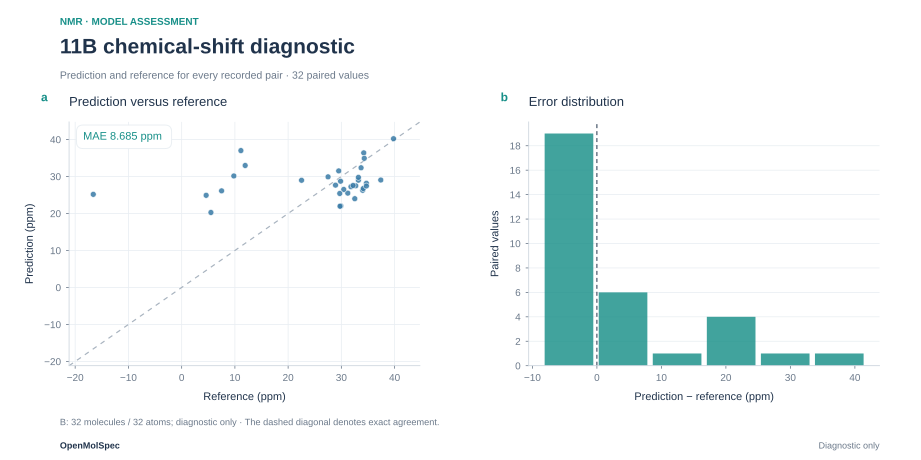

In [4]:
figure = render('nmr.forward.11B', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## 重新执行模型

按任务页面与 Quick Start 配置原模型运行环境、checkpoint 和数据。上面的分析单元格只需要文档示例环境。

[Task](../tasks/nmr-forward-11B.md) · [Quick Start](../quickstart.md)
